# GitHub Developer Visibility Risk Prediction
### Behavioral analytics on 21,000 real GitHub developer profiles

**Problem.** Recruiters and hiring tools use GitHub as a first filter, and follower count is the most visible signal of a developer's reach. Many capable developers, especially freshers, have profiles that get little traction and don't know why.

**Objective.** Predict a developer's **visibility risk**: the chance their profile sits in a low-follower band (**High** risk: 0–19 followers, **Medium**: 20–99, **Low**: 100+). The model uses **only activity and profile signals the developer controls**, then explains which signals raise or lower the risk.

**Leakage rule.** The target comes from `followers`, so no follower-derived column may be a model input. Version 1 of this project broke that rule (see section 1).

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sys.path.insert(0, "src")
from features import FEATURES, LEAKY_COLUMNS, SKEWED, CLASS_NAMES, engineer, make_target

raw = pd.read_csv("dataset/developers_features_engineered.csv")
print(raw.shape)
raw.head()

(21000, 25)


,followers,following,public_repos,public_gists,account_created_at,account_age_days,bio_length,hireable,site_admin,type,...,repo_gist_ratio,experience_score,repos_per_year,has_bio,has_company,has_location,profile_completeness,engagement_index,productivity_proxy,influence_density
0,974,0,0,0,2016-02-09 22:54:25+00:00,3650,0,0,0,User,...,0.000000,8.202756,0.000000,0,0,0,0,974,0.000000,974.000000
1,611,1,55,17,2011-11-05 13:33:24+00:00,5208,79,1,0,User,...,3.055556,8.558143,3.602189,1,1,1,4,706,470.697875,10.910714
2,148,1,3,0,2015-09-16 09:06:09+00:00,3797,0,0,0,User,...,3.000000,8.242230,0.263095,0,1,0,1,161,24.726690,37.000000
3,556,0,39,2,2010-07-30 04:46:49+00:00,5671,12,0,0,User,...,13.000000,8.643297,2.358350,1,1,1,3,625,337.088586,13.900000
4,947,366,98,4,2010-07-05 11:26:31+00:00,5696,151,0,0,User,...,19.600000,8.647695,5.901666,1,1,1,3,1075,847.474110,9.565657


## 1. Why v1 scored 99%: target leakage

v1 defined `stability_score` from `popularity_score`, `project_density`, `experience_score` and `engagement_index`, binned it into 3 classes, and then trained models on **those same columns**. The models were relearning a formula, not predicting anything. Recomputing that score and fitting a depth-2 tree on it alone reproduces the v1 accuracy:

In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
n = lambda s: (s - s.min()) / (s.max() - s.min())
v1_score = (n(raw.popularity_score)*.30 + n(raw.project_density)*.25
            + n(raw.experience_score)*.25 + n(raw.engagement_index)*.20)
lo, hi = v1_score.quantile([.33, .66])
v1_label = np.where(v1_score >= hi, 0, np.where(v1_score >= lo, 1, 2))
acc = cross_val_score(DecisionTreeClassifier(max_depth=2), v1_score.to_frame(), v1_label, cv=5).mean()
print(f"Depth-2 tree on the v1 formula alone: {acc:.2%} accuracy -> the 99% was leakage")

Depth-2 tree on the v1 formula alone: 99.98% accuracy -> the 99% was leakage


## 2. Data cleaning and the new target

In [3]:
df = raw[raw["type"].eq("User")].drop_duplicates()
print(f"Removed {len(raw) - len(df)} bot accounts -> {len(df):,} developers")
y = make_target(df["followers"])
X = engineer(df)[FEATURES]
assert not set(X.columns) & set(LEAKY_COLUMNS)
print("Inputs:", FEATURES)
print("Excluded (contain followers):", [c for c in LEAKY_COLUMNS if c in raw.columns])
y.map({0: "High", 1: "Medium", 2: "Low"}).value_counts()

Removed 36 bot accounts -> 20,964 developers
Inputs: ['public_repos', 'public_gists', 'total_projects', 'repos_per_year', 'project_density', 'repo_gist_ratio', 'account_age_days', 'following', 'bio_length', 'has_bio', 'has_company', 'has_location', 'hireable', 'profile_completeness']
Excluded (contain followers): ['followers', 'popularity_score', 'follower_following_ratio', 'influence_score', 'engagement_index', 'influence_density']


followers
High      7224
Low       6948
Medium    6792
Name: count, dtype: int64

## 3. Exploratory analysis

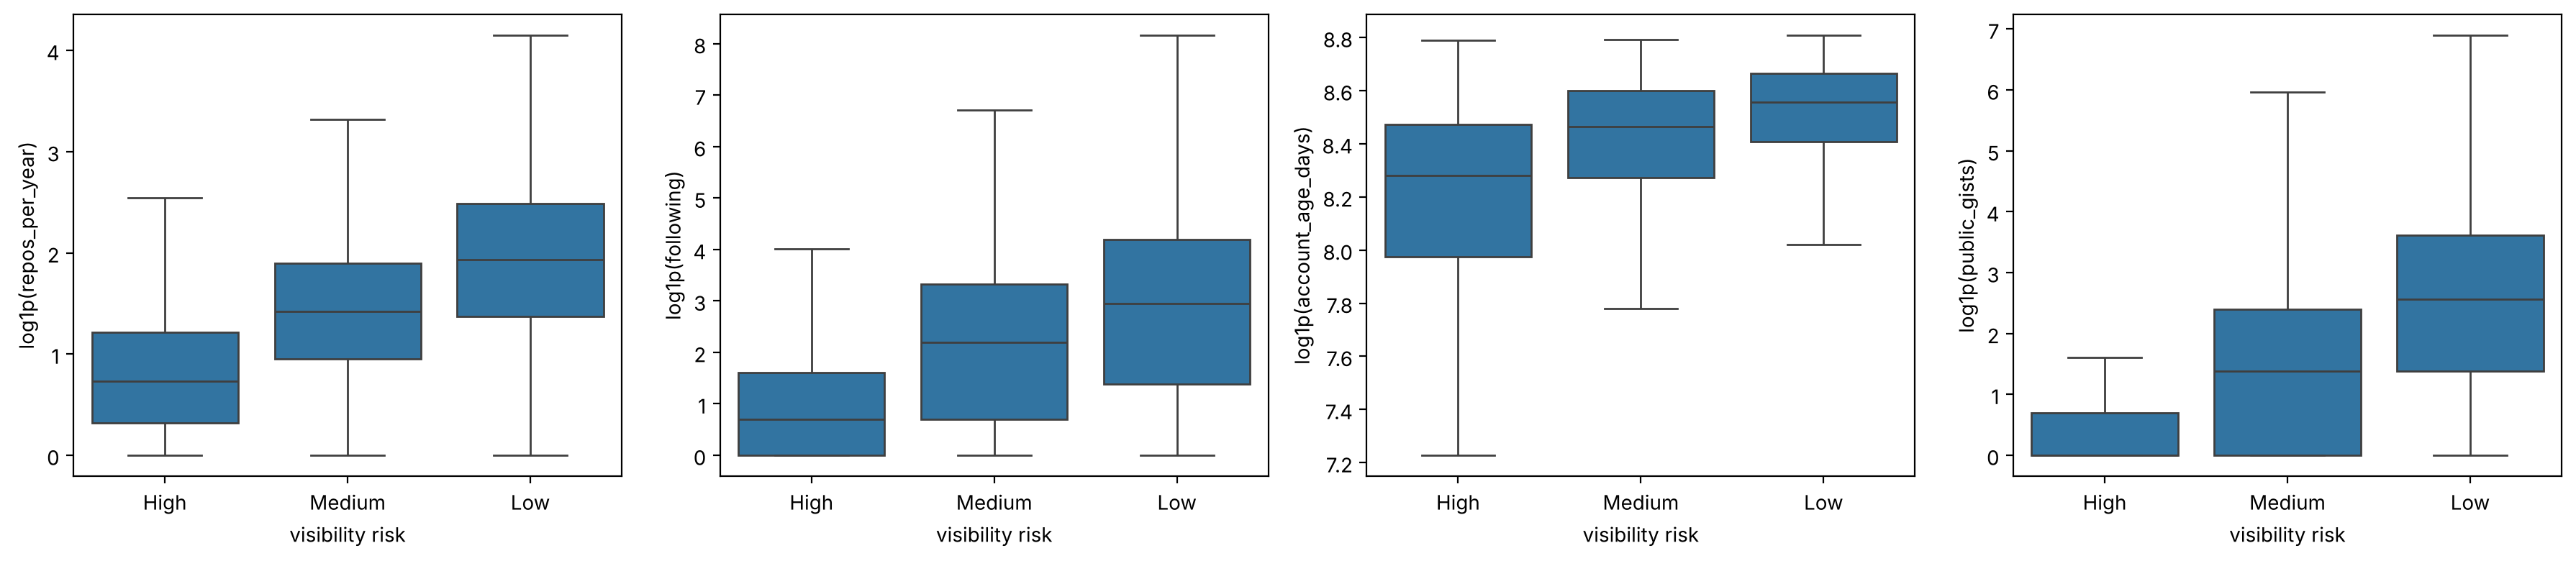

,has_bio,has_company,has_location,hireable
risk,,,,
High,0.209,0.316,0.414,0.096
Medium,0.391,0.500,0.695,0.197
Low,0.585,0.604,0.793,0.231


In [4]:
plot = X.assign(risk=y.map({0: "High", 1: "Medium", 2: "Low"}))
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["repos_per_year", "following", "account_age_days", "public_gists"]):
    sns.boxplot(data=plot, x="risk", y=np.log1p(plot[col]), order=["High", "Medium", "Low"], ax=ax, showfliers=False)
    ax.set_ylabel(f"log1p({col})"); ax.set_xlabel("visibility risk")
plt.tight_layout(); plt.show()

rates = plot.groupby("risk")[["has_bio", "has_company", "has_location", "hireable"]].mean().loc[["High", "Medium", "Low"]]
rates.round(3)

**Observations**
- Low-risk (high-visibility) profiles publish more repos per year, follow more people and have older accounts.
- Every profile field (bio, company, location, hireable) is filled in more often as visibility rises. Only 21% of high-risk profiles have a bio, against 59% of low-risk ones.

## 4. Train / test split and models
Stratified 80/20 split. Every model is scored with 5-fold CV on the training set **only**, and the final model is picked by CV macro-F1, never by test score.

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from xgboost import XGBClassifier

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
skew_idx = [FEATURES.index(c) for c in SKEWED]
models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("log", ColumnTransformer([("log", FunctionTransformer(np.log1p), skew_idx)], remainder="passthrough")),
        ("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=2000, random_state=42))]),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, min_child_weight=5, eval_metric="mlogloss", random_state=42),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    r = cross_validate(m, X_tr, y_tr, cv=cv, scoring=["accuracy", "f1_macro"])
    m.fit(X_tr, y_tr)
    rows.append({"model": name, "cv_acc": r["test_accuracy"].mean(), "cv_f1": r["test_f1_macro"].mean(),
                 "train_acc": m.score(X_tr, y_tr), "test_acc": m.score(X_te, y_te)})
results = pd.DataFrame(rows).set_index("model").round(3)
results

,cv_acc,cv_f1,train_acc,test_acc
model,,,,
Baseline (majority),0.345,0.171,0.345,0.345
Logistic Regression,0.635,0.629,0.636,0.636
Random Forest,0.629,0.624,0.826,0.628
XGBoost,0.634,0.629,0.721,0.640


**Reading the results**
- Every real model beats the majority-class baseline (~34%) by about 30 points.
- Logistic Regression and XGBoost are tied on CV. Random Forest overfits (high train, lower test).
- **Logistic Regression is selected**: same accuracy, train ≈ test (no overfitting), and its explanations are exact.
- Around 64% on a 3-class problem is believable for profile-only signals. Visibility also depends on things not on a profile (talks, blog posts, employer brand).

                            precision    recall  f1-score   support

High Risk (low visibility)       0.72      0.76      0.74      1445
               Medium Risk       0.50      0.46      0.48      1358
Low Risk (high visibility)       0.67      0.67      0.67      1390

                  accuracy                           0.64      4193
                 macro avg       0.63      0.63      0.63      4193
              weighted avg       0.63      0.64      0.63      4193

ROC-AUC (OvR): 0.817


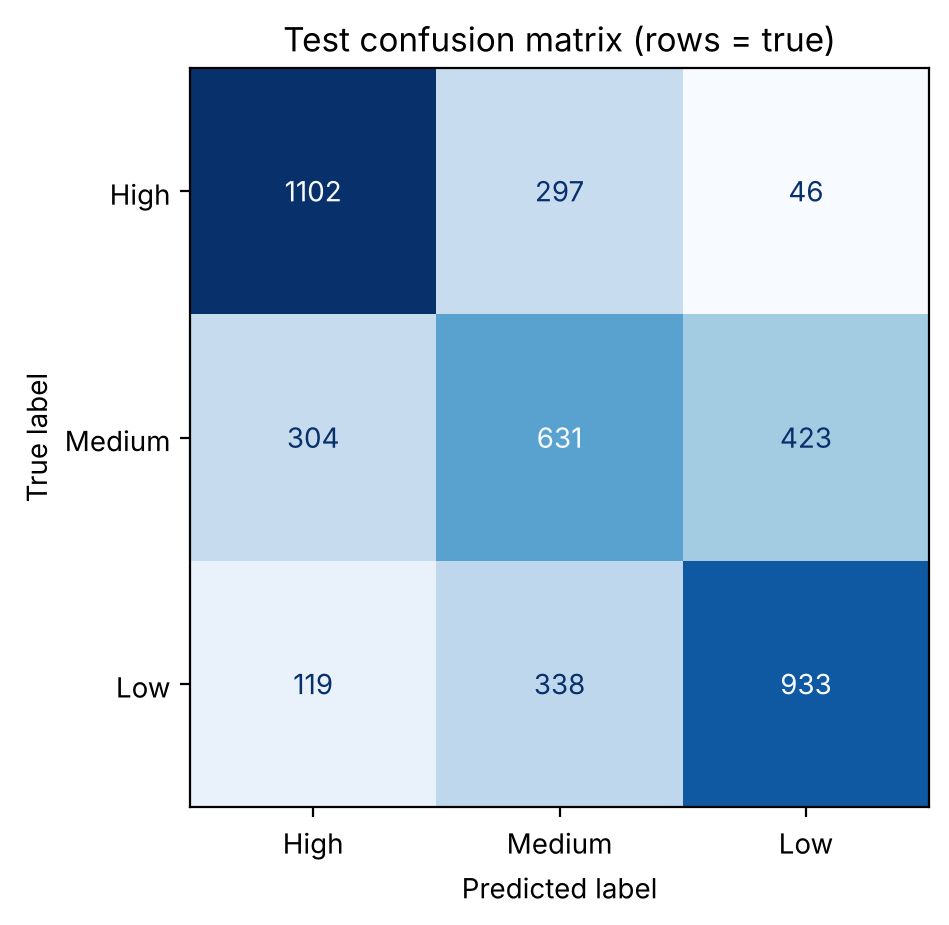

In [6]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score
best = models["Logistic Regression"]
pred = best.predict(X_te)
print(classification_report(y_te, pred, target_names=[CLASS_NAMES[i] for i in range(3)]))
print("ROC-AUC (OvR):", round(roc_auc_score(y_te, best.predict_proba(X_te), multi_class="ovr"), 3))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["High", "Medium", "Low"], cmap="Blues", colorbar=False)
plt.title("Test confusion matrix (rows = true)"); plt.show()

Most errors fall in the **Medium** class, between its neighbours. The model almost never mistakes High for Low or the other way round, so it is reliable at the extremes, which matter most.

## 5. Explainability (SHAP)
For a linear model, SHAP values are exact: `coefficient × standardized feature value` in log-odds.

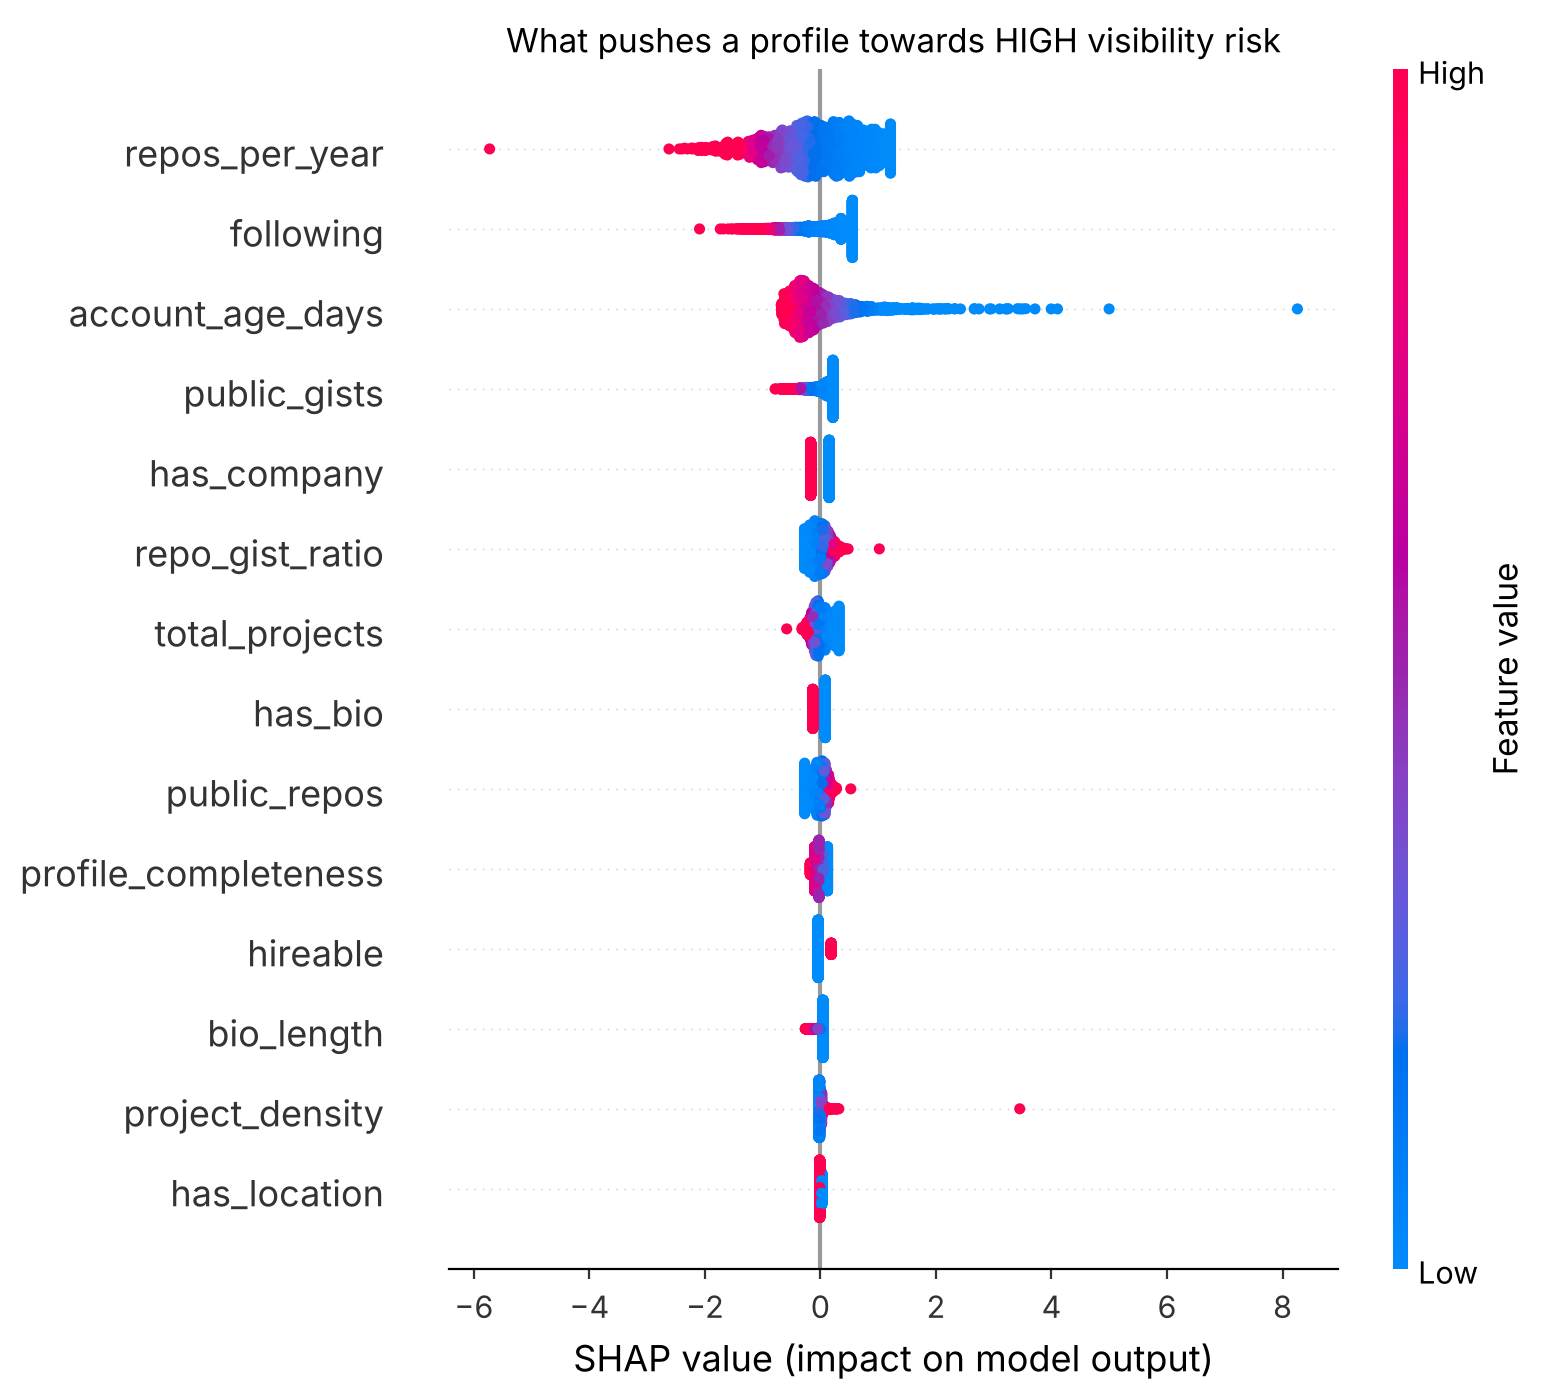

In [7]:
import shap
from explain import contributions
sample = X_te.sample(2000, random_state=42)
sv = contributions(best, sample)
shap.summary_plot(sv[:, :, 0], sample, show=False, max_display=14)
plt.title("What pushes a profile towards HIGH visibility risk"); plt.tight_layout(); plt.show()

**Key insights**
1. **Publishing cadence (`repos_per_year`) is the strongest controllable lever.** Steady output lowers risk.
2. **Following others** is strongly associated with visibility: networking is reciprocal.
3. **Account age** matters, so newer developers start at a disadvantage and need to compensate with cadence.
4. **Profile basics** (company, bio) have smaller but consistent effects and cost nothing to fix.

These are associations, not causal effects.

## 6. Deployment: score any profile
`src/train.py` refits the selected model on all data and saves `models/visibility_risk_model.joblib`. `src/predict.py` scores a live GitHub profile and explains the result:

In [8]:
from predict import score, to_text
profile = json.load(open("examples/sample_profile.json"))
print(to_text(score(profile)))

GitHub visibility risk for @example-fresher: HIGH
  probabilities  High 88% | Medium 11% | Low 0%
  actual followers: 4 (not used by the model)

Pushing risk UP:
  - Account age (days): 1565
  - Public repos created per year: 1.702
  - Public gists: 0
  - Developers you follow: 2
Pulling risk DOWN:
  - Public repos: 9
  - Profile completeness (bio/company/location/hireable): 2
  - Projects per day of account age: 0.006

What to change:
  1. Ship small public projects more regularly; one solid repo a month beats a burst of forks.
  2. Share useful snippets as gists (SQL queries, configs, scripts).
  3. Engage with the community: follow developers and projects in your field.

Model: Logistic Regression (test accuracy 64%, 3 classes)


## 7. Limitations and next steps
- **Snapshot data:** one profile snapshot (Feb 2026), so this shows association rather than causation. *Next:* a time-based version that predicts future activity decline from contribution history (needs the GitHub GraphQL contributions API).
- **Sampling bias:** developers were found through contributors of large OSS repos, so they are more active than the average GitHub user.
- **Missing signals:** stars, README quality, pinned repos and commit history aren't in the data yet.